In [1]:
import numpy as np
import pandas as pd
import wfdb
import os
import sys
from scipy import signal
from scipy.signal import butter, filtfilt
from wfdb.processing import resample_singlechan
import matplotlib.pyplot as plt
import pywt
import json
import glob
import random
from scipy.io import loadmat

In [2]:
def butter_bandpass(lowcut, highcut, fs, order=5):
    nyq = 0.5 * fs
    low = lowcut / nyq
    high = highcut / nyq
    b, a = butter(order, [low, high], btype='band')
    return b, a
 
def butter_bandpass_filter(data, lowcut, highcut, fs, order=5):
    b, a = butter_bandpass(lowcut, highcut, fs, order=order)
    y = filtfilt(b, a, data)
    return y

def calc_baseline(signal):
    ssds = np.zeros((3))
    cur_lp = np.copy(signal)
    iterations = 0
    while True:
        # Decompose 1 level
        lp, hp = pywt.dwt(cur_lp, "db4")

        # Shift and calculate the energy of detail/high pass coefficient
        ssds = np.concatenate(([np.sum(hp ** 2)], ssds[:-1]))

        # Check if we are in the local minimum of energy function of high-pass signal
        if ssds[2] > ssds[1] and ssds[1] < ssds[0]:
            break

        cur_lp = lp[:]
        iterations += 1

    # Reconstruct the baseline from this level low pass signal up to the original length
    baseline = cur_lp[:]
    for _ in range(iterations):
        baseline = pywt.idwt(baseline, np.zeros((len(baseline))), "db4")

    return baseline[: len(signal)]

def normalizing(ecg):
    ecg = (ecg - ecg.min()) / (ecg.max() - ecg.min())
    return ecg

def preprocessing(ecg):
    ecg = signal.savgol_filter(ecg, 25, 3)
    ecg = normalizing(ecg)
    return ecg

In [28]:
afib = set([100, 101, 103, 105, 108, 109, 111, 112, 201, 202, 203, 210, 217, 219, 221, 222])

In [3]:
annot = pd.read_csv(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\raw\ConditionNames_SNOMED-CT.csv')
encode_label = {
    'N' : 0,
    'AFIB' : 1,
    '1AVB' : 2,
    'LBBB' : 3,
    'RBBB' : 4,
    'PAC' : 5,
    'PVC' : 6,
    'STD' : 7,
    'STE' : 8,
}
ct_to_label = dict()
for ct, name in zip(annot['Snomed_CT'], annot['Acronym Name']):
    ct_to_label[ct] = name
# ct_to_label

In [4]:
%matplotlib qt5

import wfdb.processing


cur_dir = os.getcwd()
db_dir = r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\raw\CPSC_2018\Training_WFDB'

# db_dir = os.path.join(cur_dir, 'data', 'WFDB_ChapmanShaoxing')

def most_frequent(List):
    return max(set(List), key=List.count)

In [5]:
fileList = [file for file in os.listdir(db_dir) if file.endswith('.hea')]

In [7]:
X_1 = np.load(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\CPSP2018\data_1.npy')
X_2 = np.load(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\CPSP2018\data_2.npy')
X_3 = np.load(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\CPSP2018\data_3.npy')
y_1 = np.load(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\CPSP2018\label_1.npy')
y_2 = np.load(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\CPSP2018\label_2.npy')
y_3 = np.load(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\CPSP2018\label_3.npy')

In [9]:
X = np.concatenate([X_1, X_2, X_3], axis=0)
y = np.concatenate([y_1, y_2, y_3], axis=0)
np.save(os.path.join(os.getcwd(), 'data//processed', 'CPSP2018', f'data.npy'), X)
np.save(os.path.join(os.getcwd(), 'data//processed', 'CPSP2018', f'label.npy'), y)

In [22]:
X = []
y = []
for file in fileList[10:15]:
        record_name = os.path.splitext(file)[0]
        record_path = os.path.join(db_dir, record_name)
        data = loadmat(record_path + '.mat')['val']
        with open(record_path + '.hea', 'r') as f:
            header_data = f.readlines()
        label = header_data[-4]
        label = label[label.find(' ') + 1:]
        if label.find(',') != -1:
            label = ct_to_label[int(label[:label.find(',')])]
        else:
            label = ct_to_label[int(label)]
        
        if label == 'SR':
            label = 'N'
        
        fig, axes = plt.subplots(12, 1, tight_layout=True, figsize=(10, 10))
        fig.suptitle(label)
        for i in range(12):
            axes[i].plot(data[i,:500*10])
            axes[i].xaxis.set_visible(False)
        plt.show()
        # break

In [6]:
X = []
y = []
for file in fileList:
        record_name = os.path.splitext(file)[0]
        record_path = os.path.join(db_dir, record_name)
        data = loadmat(record_path + '.mat')['val']
        with open(record_path + '.hea', 'r') as f:
            header_data = f.readlines()

        label = header_data[-4]
        label = label[label.find(' ') + 1:]
        if label.find(',') != -1:
            label = ct_to_label[int(label[:label.find(',')])]
        else:
            label = ct_to_label[int(label)]
        
        if label == 'SR':
            label = 'N'
        # print(label)
        label = encode_label[label]

        original_fs = 500
        target_fs = 256
        step = 10

        original_signal = [wfdb.processing.resample_sig(data[lead, :], original_fs, target_fs)[0] for lead in range(12)]

        window_size = target_fs * step
        signal_length = len(original_signal[0])
        for start_idx in range(0, signal_length, target_fs * 10):
            end_idx = start_idx + window_size
                
            leads = []
            ok = 1
            for lead in [0, 1, 6]:
                
                # padding
                if start_idx + window_size > signal_length:
                    segment_signal = np.pad(original_signal[lead][start_idx:signal_length], (0, end_idx - signal_length), mode='constant', constant_values=0)
                else:
                    segment_signal = original_signal[lead][start_idx:end_idx]
                filtered_signal = signal.savgol_filter(segment_signal, 25, 3)

                if(filtered_signal.min() == filtered_signal.max()):
                    ok = 0
                    break
                leads.append(list(normalizing(filtered_signal)))
            if ok:
                X.append(leads)
                y.append(label)
            

X = np.array(X)
y = np.array(y)


In [7]:
np.save(os.path.join(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\lightx3', f'data.npy'), X)
np.save(os.path.join(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\lightx3', f'label.npy'), y)
print(X.shape, y.shape)

(13558, 3, 2560) (13558,)


In [8]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
np.save(os.path.join(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\lightx3', f'train_X.npy'), X_train)
np.save(os.path.join(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\lightx3', f'train_y.npy'), y_train)
np.save(os.path.join(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\lightx3', f'test_X.npy'), X_test)
np.save(os.path.join(r'F:\EAGLe_explanation_attention_guided_learning_for_time_series\data\processed\lightx3', f'test_y.npy'), y_test)

In [115]:
# SEGMENTATE THE WINDOW WITH 6sec and 256hz
%matplotlib qt5

cur_dir = os.getcwd()
db_dir = os.path.join(cur_dir, 'data', 'mitdb')

def most_frequent(List):
    return max(set(List), key=List.count)

for file in os.listdir(db_dir):
    if file.endswith('.hea'):
        record_name = os.path.splitext(file)[0]
        record_path = os.path.join(db_dir, record_name)

        # if int(record_name) not in afib:
        #     continue

        record = wfdb.rdrecord(record_path)
        ann = wfdb.rdann(record_path, extension='atr')

        original_signal = record.p_signal.T[0]

        original_fs = record.fs
        target_fs = 256
        step = 6

        original_signal, ann = resample_singlechan(original_signal, ann, original_fs, target_fs)

        window_size = target_fs * step
        signal_length = len(original_signal)
        label = np.array(ann.aux_note)
        sample = ann.sample
        for i in range(1, len(label)):
            if(label[i] == ''):
                label[i] = label[i - 1]
        X = []
        y = []

        # FOR AFDB
        # for i, segment_label in enumerate(label):
        #     segment_label = segment_label[1:]
        #     if segment_label == 'AFIB':
        #         start = sample[i]
        #         end_idx = 0
        #         if i == len(label) - 1:
        #             end_idx = start + 5 * window_size
        #         else:
        #             end_idx = sample[i + 1]
        #         for start_idx in range(start, end_idx, target_fs * 5):
        #             segment_signal = original_signal[start_idx:start_idx+window_size]
        #             filtered_signal = preprocessing(segment_signal)
        #             X.append(list(filtered_signal))
        #             y.append(segment_label)
        #     elif segment_label == 'N':
        #         start = sample[i]
        #         end = start + window_size * 500
        #         if i + 1 < len(label):
        #             if label[i + 1] == '(AFIB':
        #                 end = min(end, sample[i + 1])
        #         else:
        #             end = start + window_size * 100
        #         for start_idx in range(start, end, window_size):
        #             segment_signal = original_signal[start_idx:start_idx+window_size]
        #             filtered_signal = preprocessing(segment_signal)
        #             X.append(list(filtered_signal))
        #             y.append(segment_label)
        # break
        # # FOR MITDB
        for start_idx in range(0, signal_length - window_size, window_size):
            end_idx = start_idx + window_size
            beat_label = label[np.flatnonzero((sample >= start_idx) & (sample <= end_idx))]
            segment_signal = original_signal[start_idx:end_idx]
            filtered_signal = preprocessing(segment_signal)
            
            segment_label = most_frequent(list(beat_label))[1:]

            if segment_label == 'N' or segment_label == 'AFIB':
                X.append(list(filtered_signal))
                y.append(segment_label)

        X = np.array(X)
        y = np.array(y)
        np.save(os.path.join(os.getcwd(), 'data', 'afib', f'{record_name}.npy'), X)
        np.save(os.path.join(os.getcwd(), 'data', 'afib', f'{record_name}_label.npy'), y)

## HEARTBEAT SEGMENTATION

In [38]:
def dwt(ecg_signal):
        # Perform DWT decomposition
    wavelet = 'db4'  # Choose a suitable wavelet
    level = 5  # Decomposition level
    coeffs = pywt.wavedec(ecg_signal, wavelet, level=level)

    # Thresholding (Soft thresholding on detail coefficients)
    threshold = 0.04  # Adjust this based on your data
    coeffs_denoised = [coeffs[0]]  # Approximation coefficients (low-frequency remain untouched)
    coeffs_denoised += [pywt.threshold(c, threshold, mode='soft') for c in coeffs[1:]]

    # Reconstruct the signal
    denoised_signal = pywt.waverec(coeffs_denoised, wavelet)
    return denoised_signal

In [147]:
# SEGMENTATE THE WINDOW WITH 6sec and 256hz
%matplotlib qt5

annot = ['N', 'L', 'R', 'e', 'j', 'A', 'a', 'J', 'S', 'V', 'E', 'F', '/', 'f', 'Q']
p_study = set(['102', '104', '107', '217'])
cur_dir = os.getcwd()
db_dir = os.path.join(cur_dir, 'data', 'mitdb')

def most_frequent(List):
    return max(set(List), key=List.count)

X = []
y = []
for file in os.listdir(db_dir):
    if file.endswith('.hea'):
        record_name = os.path.splitext(file)[0]
        record_path = os.path.join(db_dir, record_name)
        if record_name in p_study:
            continue
        record = wfdb.rdrecord(record_path)
        ann = wfdb.rdann(record_path, extension='atr')

        original_signal = record.p_signal.T[0]
        fs = record.fs

        r_x = ann.sample
        r_label = ann.symbol
        
        for x, label in zip(r_x, r_label):
            beat = original_signal[x-99:x+201]
            if x < 100 or x + 201 >= len(original_signal):
                continue
            try:
                numeric_label = annot.index(label)
                beat = preprocessing(beat)
                if numeric_label < 5:
                    numeric_label = 0
                elif numeric_label < 9:
                    numeric_label = 1
                elif numeric_label < 11:
                    numeric_label = 2
                elif numeric_label < 12:
                    numeric_label = 3
                else:
                    numeric_label = 4
                X.append(beat)
                y.append(numeric_label)
            except ValueError:
                continue
print(len(X))

100687


In [151]:
n_X = np.array(X)
n_y = np.array(y)
n_X.shape, n_y.shape

((100687, 300), (100687,))

In [152]:
np.save(os.path.join(os.getcwd(), 'data//processed', 'mitdb', f'data.npy'), n_X)
np.save(os.path.join(os.getcwd(), 'data//processed', 'mitdb', f'label.npy'), n_y)

# INSIGHTS ABOUT THE LABELS

In [116]:
train_set = set([100, 101, 103, 105, 108, 109, 111, 112, 201, 202, 203, 210, 217, 219, 221, 222])

In [9]:
y = []
studies = []
for filepath in glob.glob(os.path.join(os.getcwd(), 'data//processed', 'CPSP2018', '*_label.npy')):
    filename = filepath.split('\\')[-1][:]
    y.append(np.load(filepath))
    studies.append(filename[:filename.find('_')])
# studies

In [30]:
rand_seg = np.random.randint(data.shape[0])
plt.title(f'LABEL: {label[rand_seg]}')
plt.plot(data[rand_seg, :])
plt.show()

In [ ]:
random.shuffle(studies)
threshold = int(len(studies) * 0.8)
train_studies = studies[:threshold]
test_studies = studies[threshold:]

In [14]:
data = np.load(os.path.join(os.getcwd(), 'data//processed', 'CPSP2018', 'data.npy'))
label = np.load(os.path.join(os.getcwd(), 'data//processed', 'CPSP2018', 'label.npy'))

In [20]:
plt.hist(label,bins=8)
plt.show()

In [19]:
train_y = []
test_y = []

for filepath in glob.glob(os.path.join(os.getcwd(), 'data//processed', 'CPSP2018', '*_label.npy')):
    filename = filepath.split('\\')[-1][:]
    filename = filename[:filename.find('_')]
    if filename in train_studies:
        train_y.append(np.load(filepath))
    else:
        test_y.append(np.load(filepath))
train_y = np.concatenate(train_y)
test_y = np.concatenate(test_y)
df = pd.DataFrame(train_y)
df_2 = pd.DataFrame(test_y)
df[0] = df[0].astype("string")
df_2[0] = df_2[0].astype("string")
print(df[0].value_counts(), df_2[0].value_counts())

0
4    2835
1    2084
6    1715
0    1658
7    1467
5    1345
2    1183
8     349
3     338
Name: count, dtype: Int64 0
4.0    690
1.0    510
6.0    414
7.0    377
0.0    375
5.0    350
2.0    285
8.0    123
3.0     89
Name: count, dtype: Int64


In [18]:
split = {}
split['train'] = train_studies
split['test'] = test_studies
with open(os.path.join(os.getcwd(), 'data//processed', 'CPSP2018', "split.json"), 'w') as f:
    json.dump(split, f)

<Axes: xlabel='0'>

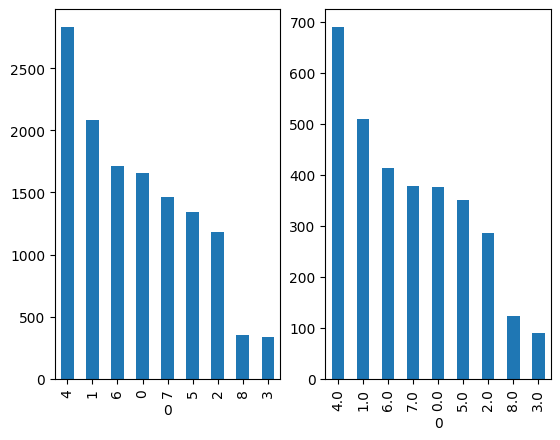

In [20]:
%matplotlib inline
plt.subplot(1, 2, 1)
df[0].value_counts().plot(kind = 'bar')
plt.subplot(1, 2, 2)
df_2[0].value_counts().plot(kind = 'bar')